In [75]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [76]:
df = pd.read_csv('ecommerce_rfm_dataset.csv')
print(df.head())

   CustomerID  Recency  Frequency  Monetary
0       10001       22          3    681.63
1       10002      136          5    527.16
2       10003       60          6    940.39
3       10004       42          2    416.99
4       10005        8          5    428.03


In [77]:
# Feature engineering bonus: Average Order Value (AOV)
df['AOV'] = df['Monetary'] / df['Frequency']

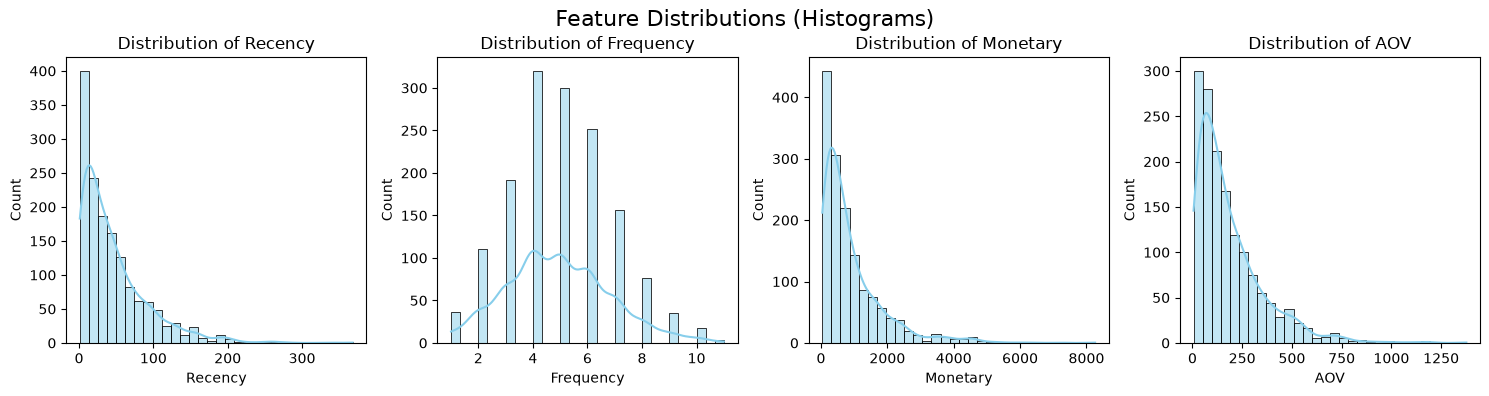

In [78]:
# ==========================================
# 2. HISTOGRAMS FOR ALL FEATURES
# ==========================================
plt.figure(figsize=(15, 4))
features = ['Recency', 'Frequency', 'Monetary', 'AOV']
for i, col in enumerate(features, 1):
  plt.subplot(1, 4, i)
  sns.histplot(df[col], kde=True, color='skyblue', bins=30)
  plt.title(f'Distribution of {col}')
  plt.xlabel(col)
  plt.ylabel('Count')
plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)  # Adjust layout to make room for suptitle
plt.suptitle('Feature Distributions (Histograms)', fontsize=16)
plt.show()

In [79]:
# 2. Preprocessing: Log Transformation & Feature Scaling
# RFM data is heavily skewed; log transformation stabilizes variance and normalizes distributions.
rfm_log = np.log1p(df[['Recency', 'Frequency', 'Monetary']])

In [80]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

In [81]:
# 4. K-Means Clustering (Evaluating Silhouette Scores across K)
inertias=[]
silhouette_scores = []
K_range = range(2, 7)

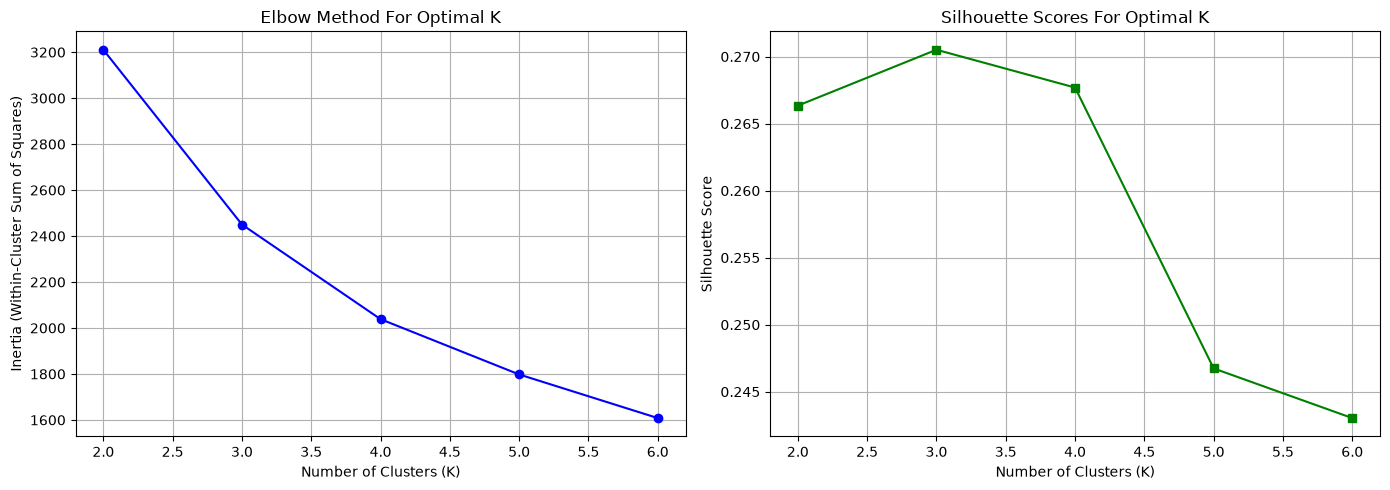

In [82]:
for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(rfm_scaled)
  inertias.append(kmeans.inertia_)
  silhouette_scores.append(silhouette_score(rfm_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method Plot
axes[0].plot(K_range, inertias, marker='o', color='b', linestyle='-')
axes[0].set_title('Elbow Method For Optimal K')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].grid(True)

# Silhouette Score Plot
axes[1].plot(K_range, silhouette_scores, marker='s', color='g', linestyle='-')
axes[1].set_title('Silhouette Scores For Optimal K')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [83]:
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans_final.fit_predict(rfm_scaled)

# Tuned DBSCAN (Adjusted eps and min_samples so clusters map correctly)
dbscan = DBSCAN(eps=0.5, min_samples=10)
df['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

In [84]:
# ==========================================
# 6. DIMENSIONALITY REDUCTION (PCA & t-SNE)
# ==========================================
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
rfm_tsne = tsne.fit_transform(rfm_scaled)

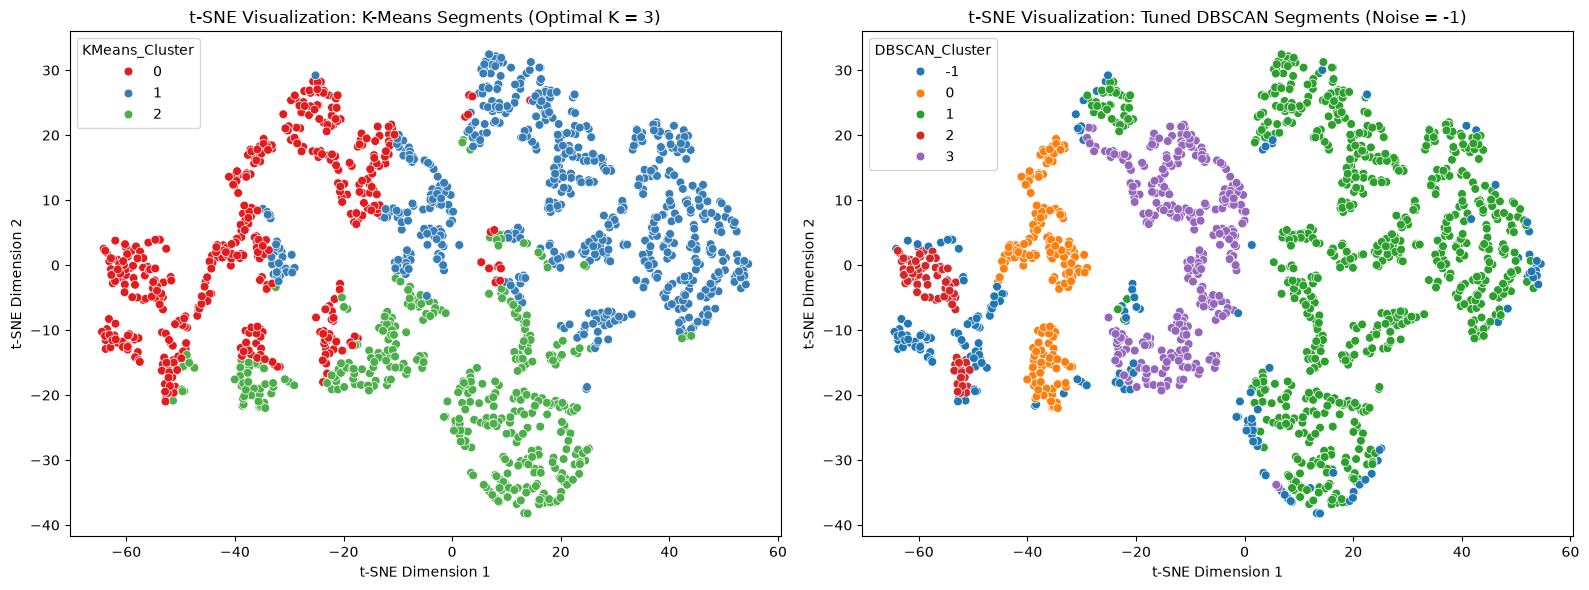

In [85]:
# ==========================================
# 7. VISUALIZATION (K-MEANS K=3 vs DBSCAN)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: K-Means (K=3) t-SNE Scatter Plot
sns.scatterplot(
    x=rfm_tsne[:, 0],
    y=rfm_tsne[:, 1],
    hue=df['KMeans_Cluster'],
    palette='Set1',
    ax=axes[0],
    s=40,
    legend='full',
)
axes[0].set_title('t-SNE Visualization: K-Means Segments (Optimal K = 3)')
axes[0].set_xlabel('t-SNE Dimension 1')
axes[0].set_ylabel('t-SNE Dimension 2')
# Subplot 2: Tuned DBSCAN t-SNE Scatter Plot
sns.scatterplot(
    x=rfm_tsne[:, 0],
    y=rfm_tsne[:, 1],
    hue=df['DBSCAN_Cluster'],
    palette='tab10',
    ax=axes[1],
    s=40,
    legend='full',
)
axes[1].set_title('t-SNE Visualization: Tuned DBSCAN Segments (Noise = -1)')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')

plt.tight_layout()
plt.show()

In [86]:
# ==========================================
# 8. CLUSTER PROFILING & 3-PERSONA MAPPING
# ==========================================
cluster_summary = (
    df.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary', 'AOV']]
    .mean()
    .round(2)
)
cluster_summary['Customer_Count'] = df.groupby('KMeans_Cluster')[
    'CustomerID'
].count()
print('\n--- K-Means (K=3) Cluster Profiles & Marketing Personas ---')
print(cluster_summary)


--- K-Means (K=3) Cluster Profiles & Marketing Personas ---
                Recency  Frequency  Monetary     AOV  Customer_Count
KMeans_Cluster                                                      
0                 47.56       3.26    264.19  105.46             449
1                 69.24       5.87   1282.98  230.08             634
2                  8.61       5.22    992.52  202.02             417
